<a href="https://colab.research.google.com/github/deivsonpires/analise-de-dados-em-python/blob/main/An%C3%A1lise%20Parcial/An%C3%A1lise_de_dados_parcial.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


def preparar_dados():
    arquivos = [
        'marathon_results_2015.csv',
        'marathon_results_2016.csv',
        'marathon_results_2017.csv'
    ]
    df = pd.concat([pd.read_csv(arq) for arq in arquivos], ignore_index=True)
    df = df.drop_duplicates()

    colunas_tempo = ['5K', '10K', '15K', '20K', 'Half', '25K', '30K', '35K', '40K', 'Official Time']
    for col in colunas_tempo:
        df[col] = pd.to_timedelta(df[col], errors='coerce').dt.total_seconds() / 60

    df = df.dropna(subset=colunas_tempo).copy()

    df['Segunda_Metade'] = df['Official Time'] - df['Half']
    df['Estrategia'] = np.where(df['Segunda_Metade'] < df['Half'], 'Começou Devagar', 'Começou Acelerado')

    marcos = ['5K', '10K', '15K', '20K', '25K', '30K', '35K', '40K']
    df['Ritmo_5K'] = df['5K'] / 5
    for i in range(1, len(marcos)):
        df[f'Ritmo_{marcos[i]}'] = (df[marcos[i]] - df[marcos[i - 1]]) / 5

    colunas_ritmo = [f'Ritmo_{m}' for m in marcos]
    df['Desvio_Ritmo'] = df[colunas_ritmo].std(axis=1)
    df['Variacao_Ritmo'] = pd.qcut(
        df['Desvio_Ritmo'],
        q=3,
        labels=['Baixa Variação', 'Média Variação', 'Alta Variação']
    )
    return df, colunas_ritmo


df, colunas_ritmo = preparar_dados()
print('Registros válidos:', len(df))

Registros válidos: 79038


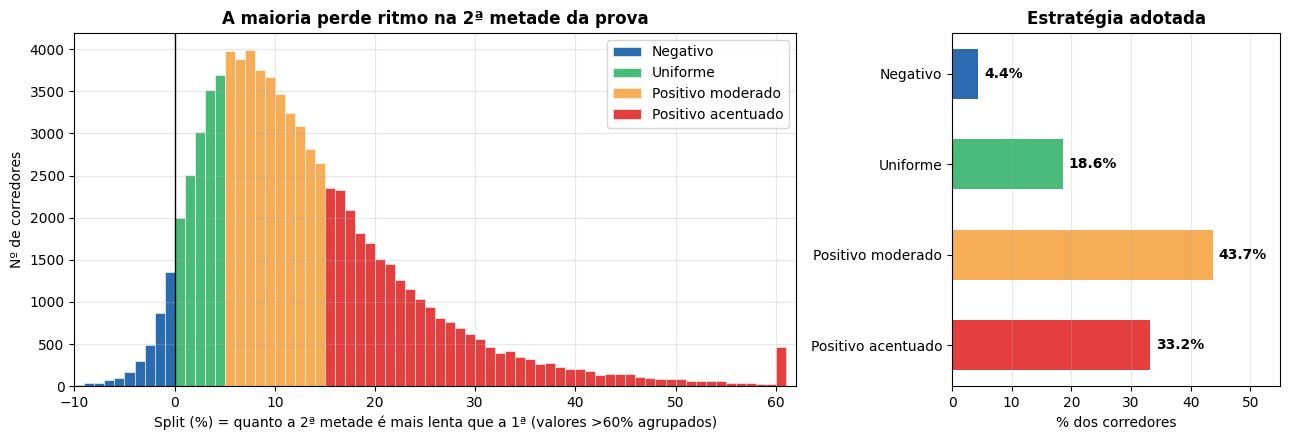

In [3]:
def analise_parcial(df):
    split_pct = ((df['Segunda_Metade'] - df['Half']) / df['Half']) * 100
    categorias = ['Negativo', 'Uniforme', 'Positivo moderado', 'Positivo acentuado']
    condicoes = [split_pct < 0, split_pct <= 5, split_pct <= 15]
    grupo = pd.Series(np.select(condicoes, categorias[:3], default=categorias[3]), index=df.index)

    cores = ['#2b6cb0', '#48bb78', '#f6ad55', '#e53e3e']
    bins = np.arange(-10, 62, 1)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={'width_ratios': [2.2, 1]})

    for cat, cor in zip(categorias, cores):
        ax1.hist(split_pct.clip(upper=60)[grupo == cat], bins=bins, color=cor, edgecolor='white', linewidth=0.4, label=cat)

    ax1.axvline(0, color='black', linewidth=1)
    ax1.set_title('A maioria perde ritmo na 2ª metade da prova', fontweight='bold')
    ax1.set_xlabel('Split (%) = quanto a 2ª metade é mais lenta que a 1ª (valores >60% agrupados)')
    ax1.set_ylabel('Nº de corredores')
    ax1.set_xlim(-10, 62)
    ax1.legend()
    ax1.grid(alpha=0.3)

    percentuais = (grupo.value_counts(normalize=True).reindex(categorias) * 100)[::-1]
    barras = ax2.barh(percentuais.index, percentuais.values, color=cores[::-1], height=0.55)
    ax2.bar_label(barras, fmt='%.1f%%', padding=4, fontweight='bold')
    ax2.set_title('Estratégia adotada', fontweight='bold')
    ax2.set_xlabel('% dos corredores')
    ax2.set_xlim(0, 55)
    ax2.grid(axis='x', alpha=0.3)

    plt.tight_layout()
    plt.show()


analise_parcial(df)